# Settings

In [6]:
from scripts.general_nn import generalNN
from scripts import plots
import importlib


from dataclasses import replace

from scripts.general_nn import generalNN
from scripts.settings import Settings
from scripts import plots


# Use a small training budget for this first experiment.
settings = Settings(
    warmup_updates=100,
    continuation_updates=100,
    number_of_replicates=1,

    # Check validation performance every 25 training updates.
    validation_interval=25,

    # Set the sizes of the calibration, validation, and test datasets.
    normalization_size=2048,
    validation_size=2048,
    test_size=8192,

    # Used only if we choose to train from a fixed dataset.
    static_training_size=8192,
)

# Construct Models

In [15]:
# dynamic_data:
# True: generate fresh training batches during each iteration.
# False: sample batches from one fixed training dataset.

# Create a new paper-style model that trades using stock and the variance information.
paper = generalNN(
    method="paper",
    settings=settings,
    dynamic_data=False,
    name="Paper network: stock + variance",
)

# Create our new model using the same settings, including the same instruments from the paper example.
ours_settings = replace(
    settings,
    instruments=paper.settings.instruments,
)
ours = generalNN(
    method="ours",
    settings=ours_settings,
    dynamic_data=True,
    name="Our network: stock + variance",
)

# Training and Evaluation

In [16]:
# Train and evaluate each newly created model.
for model in (paper, ours):

    print(f"\nTraining: {model.name}")

    # Prepare the training data and fit the hedging policies.
    model.train(verbose=True)

    # Measure the trained policies on separate test paths.
    model.evaluate()


Training: Paper network: stock + variance
paper_full_0_warmup: update 0, validation risk 6.40759
paper_full_0_warmup: update 100, validation risk 2.66880
paper_full_0_CVaR: update 0, validation risk 2.67375
paper_full_0_CVaR: update 100, validation risk 2.56541
paper_full_0_Entropic: update 0, validation risk 7.91964
paper_full_0_Entropic: update 100, validation risk 4.23089

Training: Our network: stock + variance
ours_0_warmup: update 0, validation risk 4.29552
ours_0_warmup: update 100, validation risk 2.41511
ours_0_CVaR: update 0, validation risk 2.41511
ours_0_CVaR: update 100, validation risk 2.35628
ours_0_Entropic: update 0, validation risk 2.40280
ours_0_Entropic: update 100, validation risk 2.09711


# Display Experiment Results

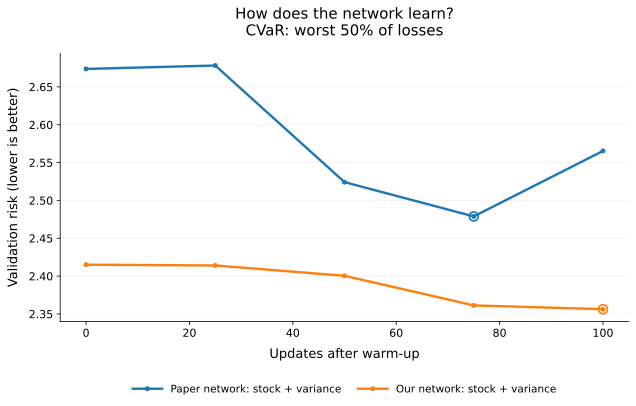

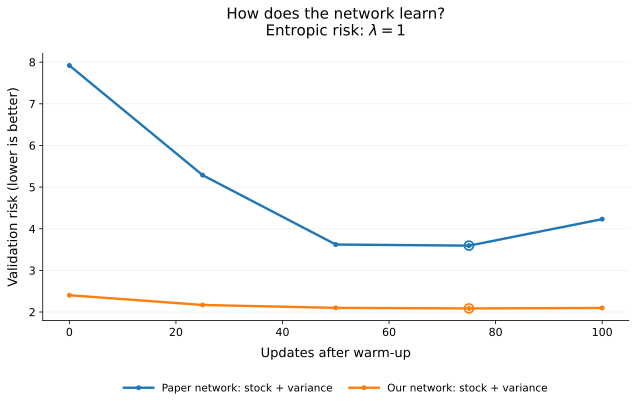

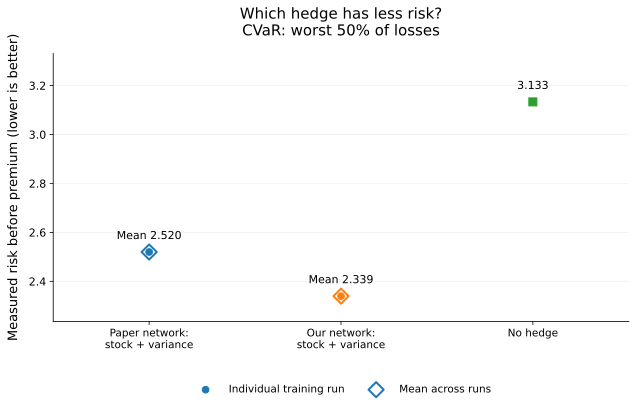

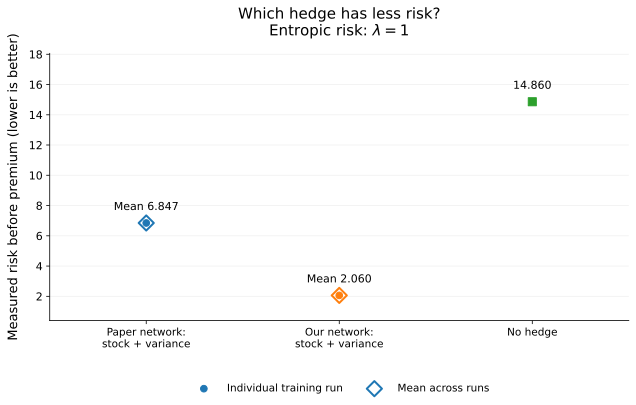

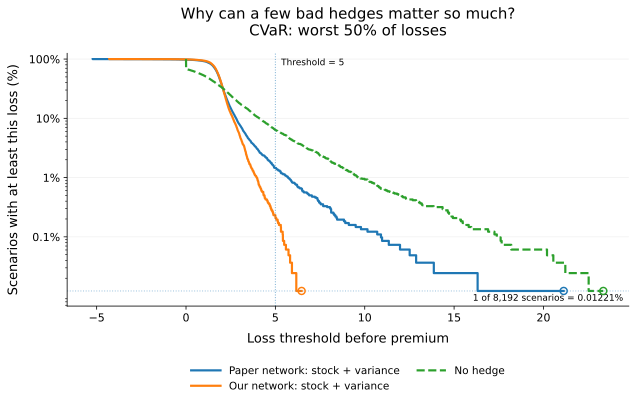

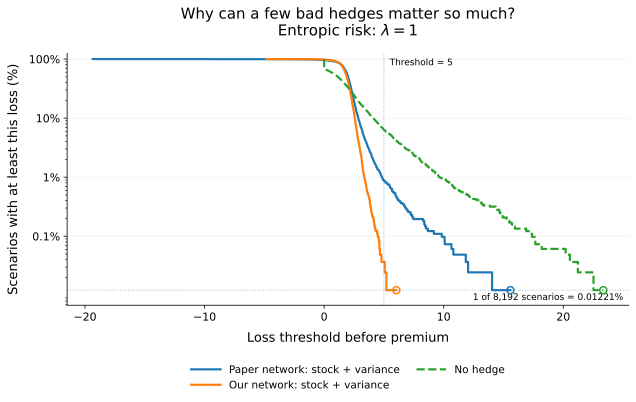

In [17]:
experiments = [paper, ours]

plots.plot_learning(experiments)
plots.plot_risk(experiments)
plots.plot_loss_tails(experiments)